# TSARA, Phase 3.6 — clocks

**A walkthrough you can run, change and try to break.** Every number and figure
below is produced by the package from air the generator manufactures, with
every plume it injected and every clock error it wrote recorded, so the right
answer is always known. No real measurement is read, and nothing needs
mounting.

---

## How to use this notebook

1. **Run everything once** (*Run All*, about a minute).
2. **Every section stands on its own.** Each opens with a **parameters cell**:
   a short list of CAPITALISED names, each commented with what it controls.
   Change a value, then run that section's cells from the parameters cell down
   to the next heading. Sections share only the setup cell below.
3. **Sections §2 to §6 print checks** (§1 uses no TSARA, so it has none). A
   line beginning ✔ is a claim about TSARA,
   compared *as it ran* against something written independently in this
   notebook: a plain loop written from the definition, or the clock error the
   archive was written with. The checks are written to hold at *any*
   parameters. If you ever see ✘, you have found an edge case worth
   understanding or a bug.
4. **"Try it"** notes after each section suggest a change and say what should
   happen. Each prediction was run before this notebook was committed.
5. **The last section** collects every check into one scoreboard.

---

## What this phase delivers

Phase 3.5 settled *what interval* of air each value describes. This phase
settles *when*: how one instrument's clock relates to another's, how that is
measured from the data, and how a correction is declared and applied
(`METHODS.md` §12).

| | Property | Section |
|---|---|---|
| 1 | **A clock error costs a fit within seconds**: two analyzers of one gas, per-plume fits as one is moved | §1 |
| 2 | **A correction table**, declared beside the manifest and applied to each file as it is read | §2 |
| 3 | **One segment's lag**, from the plumes two instruments share | §3 |
| 4 | **The survey**: every segment, the chain to one reference clock, the rows of a table | §4 |
| 5 | **What it names instead of fitting**: a drift, an outlier, an undecided stretch | §5 |
| 6 | **The loop closed**: the survey's own table applied, and surveyed again | §6 |

What this phase does **not** do: read a real campaign (that is the SLC-SOS
work that follows), or measure anything but clocks (a precision, a
decorrelation time) — the survey is built so those can join it later.

---

## Vocabulary used throughout

| term | meaning |
|---|---|
| **reading** | one value an instrument wrote, with the interval of air it describes |
| **recorded clock** | the time a file wrote beside each reading, right or wrong |
| **lag** | how many seconds later one file puts the same air than another: the difference between the clocks plus the difference in inlet and response times. Measured by the survey; positive for the later file |
| **shift** | a signed duration *added* to a reading's recorded time to correct it, the sign rule of `time_shift`: a clock reading 5 s late takes −5 s. The survey writes minus the lag |
| **reference clock** | the clock every instrument is put on, named by the instrument that keeps it |
| **correction table** | a CSV of rows, each a stretch of one instrument on its recorded clock and the shift that puts it on the reference clock (`Manifest.clock_corrections`) |
| **tracer pair** | a variable on each of two instruments expected to show the same plumes: one gas on two analyzers, or gases emitted together |
| **tier** | an instrument's tracer pairs are ranked; the first tier that decides a segment sets its lag, the others check it |
| **segment** | a contiguous stretch of a record; the survey measures one lag on each |
| **wiggles** | a variable minus its centred running median: its plumes without the slow background |
| **resolution** | the step a lag is measured in: a whole second by default, finer when asked (`METHODS.md` §12.4) |
| **clock step**, **clock drift** | a lag that jumps between segments, and one that changes steadily across a stretch |
| **survey** | `tsara.survey`: measures what a manifest can declare but files do not state, and writes a table a person reviews. Never applied by itself |

---
## Setup (run this cell first)

The **toolkit**: imports, the figure style shared by notebooks 01–08, the
**reference implementations** the checks compare TSARA against, the
scoreboard, and the **recipes** that manufacture air and write it on wrong
clocks.

In [1]:
# =============================================================================
# TOOLKIT. Every section needs this cell and nothing else from other sections.
# =============================================================================
import logging
import tempfile
from functools import cache
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from tsara import setup_logging
from tsara.config.loader import load_manifest
from tsara.config.survey import SurveyConfig
from tsara.config.synthetic import SyntheticConfig
from tsara.core.clocks import read_clock_corrections, write_clock_corrections
from tsara.ingest import ingest_campaign
from tsara.survey import (
    FAULT_KINDS,
    load_clock_survey,
    pooled_lag,
    save_clock_survey,
    seconds_series,
    survey_clocks,
)
from tsara.survey.lags import cell_series, refined_lag
from tsara.synthetic import generate
from tsara.synthetic.export import ClockError, export_raw

# --- 1. figure style (identical to notebooks 01-07) --------------------------
C1, C2, C3 = "#0072b2", "#e69f00", "#009e73"  # Okabe-Ito blue, amber, green: colour-blind safe
C4 = "#cc79a7"  # Okabe-Ito purple, for a fourth series
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "normal",
        "axes.titlelocation": "left",
        "axes.labelsize": 9.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "grid.color": GRID,
        "grid.linewidth": 0.7,
        "grid.linestyle": "-",
        "legend.frameon": False,
        "legend.fontsize": 9,
        "font.size": 9.5,
        "lines.linewidth": 1.4,
        "figure.dpi": 110,
    }
)


def finish(
    ax, title=None, sub=None, ylab=None, xlab=None, legend=False, grid_axis="y", loc="upper right"
):
    """Apply the shared chrome: left-aligned title, muted subtitle, hairline grid."""
    if title:
        ax.set_title(title, pad=19 if sub else 8)
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, fontsize=8.8, color=MUTED, va="bottom")
    if ylab:
        ax.set_ylabel(ylab)
    if xlab:
        ax.set_xlabel(xlab)
    if grid_axis:
        ax.grid(True, axis=grid_axis, alpha=0.9)
    ax.set_axisbelow(True)
    if legend:
        ax.legend(loc=loc)


def clock(ax, fmt="%H:%M"):
    """Label a time axis in hours and minutes, or in the format given."""
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))


# --- 2. reference implementations --------------------------------------------
# Written from the definitions, deliberately slow and plain, one value at a
# time. They share no code with TSARA. If TSARA and these agree, it is because
# both compute the definition (METHODS.md §12.4).


def reference_wiggles(stream, variable, window_s):
    """Return a variable on whole seconds minus its centred running median, by plain loops.

    Whole seconds: each timestamp floored, the first reading of each second
    kept. The median at a second is over the readings within window/2 of it,
    used when at least a quarter of the window's possible readings are there
    (and at least three). Returns {second: wiggle}.
    """
    times = stream["time"].values.astype("datetime64[ns]").astype("int64")
    values = stream[variable].values
    kept = {}
    for t, v in zip(times, values):
        second = int(t // 1_000_000_000)
        if np.isfinite(v) and second not in kept:
            kept[second] = float(v)
    seconds = sorted(kept)
    spacing = float(np.median(np.diff(seconds)))
    need = max(3, int(0.25 * window_s / spacing))
    half = window_s / 2
    out = {}
    for s in seconds:
        near = [kept[u] for u in seconds if abs(u - s) <= half]
        if len(near) >= need:
            out[s] = kept[s] - float(np.median(near))
    return out


def reference_lag(own, partner, first_s, stop_s, search_s, min_pairs):
    """Return the best lag of one segment by plain loops: own(t) against partner(t - L).

    Returns (lag, r) at the L in [-search, search] with the largest Pearson r
    over at least min_pairs paired seconds.
    """
    best = (None, -np.inf)
    for lag in range(-search_s, search_s + 1):
        x, y = [], []
        for t in range(first_s, stop_s):
            if t in own and (t - lag) in partner:
                x.append(own[t])
                y.append(partner[t - lag])
        if len(x) >= min_pairs:
            r = float(np.corrcoef(x, y)[0, 1])
            if r > best[1]:
                best = (lag, r)
    return best


# --- 3. the scoreboard -------------------------------------------------------
CHECKS = {}


def start_section(tag):
    """Forget a section's earlier checks, so re-running it replaces rather than piles up."""
    for claim in [c for c in CHECKS if c.startswith(tag + " ")]:
        del CHECKS[claim]


def check(claim, holds, detail=""):
    """Record one claim about TSARA and print whether it held just now."""
    CHECKS[claim] = (bool(holds), detail)
    mark = "✔" if holds else "✘ DOES NOT HOLD:"
    print(f"  {mark} {claim}" + (f"   [{detail}]" if detail else ""))


# --- 4. recipes ---------------------------------------------------------------
START = pd.Timestamp("2026-01-01T00:00:00")


@cache
def campaign(seed=11, duration="150min", plumes_per_hour=40.0, plume_sigma="4s"):
    """Generate three methane analyzers seeing the same plumes.

    'ref' (1 s, the reference clock), 'fast' (1 s) and 'slow' (2 s), each with
    its own noise. Cached: sections that ask for the same air share it.
    """

    def analyzer(rate, sigma):
        return {
            "native_rate": rate,
            "measures": {"ch4": {"uncertainty": {"random": {"absolute": sigma}}}},
        }

    config = SyntheticConfig.model_validate(
        {
            "name": "clocks",
            "start": "2026-01-01T00:00:00Z",
            "duration": duration,
            "seed": seed,
            "platform": {"kind": "stationary", "latitude": 40.0, "longitude": -111.0},
            "atmosphere": {
                "fields": {
                    "ch4": {"units": "ppb", "background": {"kind": "parametric", "offset": 1950.0}}
                },
                "sources": {
                    "street": {
                        "rate_per_hour": plumes_per_hour,
                        "reference_species": "ch4",
                        "shape": {"kind": "gaussian", "sigma": plume_sigma},
                        "amplitude": {"kind": "lognormal", "median": 80.0, "sigma_log": 0.6},
                    }
                },
            },
            "instruments": {
                "ref": analyzer("1s", 1.0),
                "fast": analyzer("1s", 2.0),
                "slow": analyzer("2s", 1.5),
            },
        }
    )
    return generate(config)


@cache
def archive(errors, seed=11, duration="150min"):
    """Write a campaign's files on wrong clocks, with the table that would undo them.

    ``errors`` is a tuple of (instrument, start, end, seconds ahead). Returns
    (dataset, manifest without the table, path of the exporter's own table).
    """
    dataset = campaign(seed=seed, duration=duration)
    clock_errors = {}
    for name, start, end, ahead in errors:
        clock_errors.setdefault(name, []).append(ClockError(start, end, f"{ahead}s"))
    folder = Path(tempfile.mkdtemp()) / "archive"
    manifest = load_manifest(
        export_raw(dataset, folder, clock_errors=clock_errors, reference_clock="ref")
    )
    truth_table = manifest.clock_corrections[0]
    return dataset, manifest.model_copy(update={"clock_corrections": ()}), truth_table


def survey_settings(segment="30min", min_r=0.6, tolerance="2s", **more):
    """Return survey settings for the three analyzers.

    'fast' is measured against 'ref'; 'slow' against 'fast' first and 'ref' as a backup.
    """
    return SurveyConfig.model_validate(
        {
            "reference_clock": "ref",
            "segment": segment,
            "min_r": min_r,
            "tolerance": tolerance,
            "tracers": {
                "fast": [{"partner": "ref", "pairs": [["ch4", "ch4"]]}],
                "slow": [
                    {"partner": "fast", "pairs": [["ch4", "ch4"]]},
                    {"partner": "ref", "pairs": [["ch4", "ch4"]]},
                ],
            },
            **more,
        }
    )


def lag_panel(ax, survey, name, truth=None, color=C1):
    """Plot each segment's lag to the reference clock, the rows written, and the truth.

    Points: decided segments; a cross: one set aside as an outlier; grey: a
    segment with readings but no decision, left uncorrected; solid lines: the
    rows the survey wrote, minus their shift (a drift row slopes); dashed: the
    clock error the readings were written with.
    """
    seg = survey.segments[survey.segments.instrument == name]
    width = pd.Timedelta(survey.config.segment)
    start = pd.to_datetime(seg.start).dt.tz_localize(None)
    mid = start + width / 2
    lags = seg.lag_to_reference_s
    decided = seg.status == "decided"
    ax.plot(mid[decided], lags[decided], "o", color=color, ms=6, label="a segment's lag")
    odd = seg.status == "outlier"
    if odd.any():
        ax.plot(mid[odd], lags[odd], "X", color=C4, ms=9, label="set aside: outlier")
    none = ~seg.status.isin(["decided", "outlier", "too short"])
    for first in start[none]:
        ax.axvspan(first, first + width, color=GRID, lw=0, zorder=0)
    if none.any():
        ax.fill_between([], [], color=GRID, label="no decision")
    values = list(lags.dropna())
    for i, row in enumerate(r for r in survey.rows if r.instrument == name):
        ends = [pd.Timestamp(row.start_ns), pd.Timestamp(row.end_ns)]
        shifts = [row.shift_ns, row.shift_end_ns if row.shift_end_ns is not None else row.shift_ns]
        ax.plot(
            ends,
            [-v / 1e9 for v in shifts],
            color=INK,
            lw=2.4,
            alpha=0.45,
            label="the rows written" if i == 0 else None,
            solid_capstyle="butt",
        )
        values += [-v / 1e9 for v in shifts]
    if truth is not None:
        ax.plot(truth.index, truth.values, color=INK2, lw=1, ls="--", label="the clock error")
        values += list(truth.values)
    ax.set_ylim(min(values) - 2, max(values) + 2)
    clock(ax)

---
## §1 What a clock error costs

Two analyzers of one gas sit side by side and breathe the same air, so each
plume reaches both. Fit one's enhancement against the other's, plume by plume,
and the slope should be about 1 and the fit tight. Now move one analyzer's
clock by a few seconds, as a wrong timestamp would, and fit again.

Everything here is plain numpy on the generated air, no TSARA: this section is
the reason for the rest, so it prints no checks. A plume is a run of at least
five seconds where the first analyzer's methane stands above its two-minute
running median by the threshold below. The generated plumes are Gaussians with
a σ of 4 s, so their fits fail a little faster with the clock error than the
real van's below; the Try-it widens them.

In [2]:
# ---- PARAMETERS (section 1) ----
SEED = 11  # which manufactured campaign
PLUME_SIGMA = "4s"  # how long a plume lasts (the Gaussian's sigma)
THRESHOLD = 20.0  # ppb above the running median that makes a plume
ERRORS = [0, 1, 2, 3, 5, 10]  # seconds the second analyzer's clock is moved

In [3]:
air = campaign(seed=SEED, plume_sigma=PLUME_SIGMA)


def on_seconds(stream):
    """Methane on whole seconds, minus its centred 121 s running median."""
    values = stream["ch4"].to_series()
    values.index = values.index.floor("1s")
    values = values[~values.index.duplicated()]
    return values - values.rolling("121s", center=True).median()


ref, other = on_seconds(air.streams["ref"]), on_seconds(air.streams["fast"])
above = (ref > THRESHOLD).to_numpy().astype(int)
edges = np.flatnonzero(np.diff(np.r_[0, above, 0]))
plumes = [(ref.index[a], ref.index[b - 1]) for a, b in zip(edges[::2], edges[1::2]) if b - a >= 5]

rows = []
for error in ERRORS:
    moved = other.copy()
    moved.index = moved.index + pd.Timedelta(seconds=error)  # read `error` seconds late
    slopes, r2 = [], []
    for first, last in plumes:
        x, y = ref[first:last], moved.reindex(ref[first:last].index)
        ok = np.isfinite(y.to_numpy())
        if ok.sum() >= 5:
            slopes.append(np.polyfit(x[ok], y[ok], 1)[0])
            r2.append(np.corrcoef(x[ok], y[ok])[0, 1] ** 2)
    rows.append(
        {
            "clock error (s)": error,
            "median slope": np.median(slopes),
            "plumes with r² ≥ 0.8": np.mean(np.array(r2) >= 0.8),
        }
    )
cost = pd.DataFrame(rows).set_index("clock error (s)")
print(f"{len(plumes)} plumes\n")
print(cost.round(2).to_string())

71 plumes

                 median slope  plumes with r² ≥ 0.8
clock error (s)                                    
0                        0.99                  0.99
1                        0.94                  0.51
2                        0.77                  0.00
3                        0.53                  0.00
5                       -0.01                  0.00
10                      -0.42                  0.00


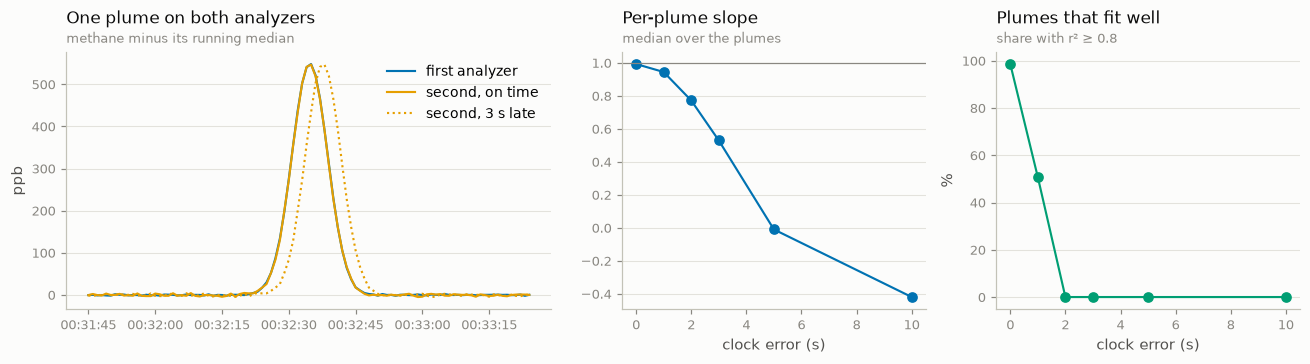

In [4]:
# Figure only.
tallest = max(plumes, key=lambda p: ref[p[0] : p[1]].max())
window = slice(tallest[0] - pd.Timedelta("40s"), tallest[1] + pd.Timedelta("40s"))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.6, 1, 1]})
late = other.copy()
late.index = late.index + pd.Timedelta(seconds=3)
axes[0].plot(ref[window].index, ref[window], color=C1, label="first analyzer")
axes[0].plot(other[window].index, other[window], color=C2, label="second, on time")
axes[0].plot(late[window].index, late[window], color=C2, ls=":", label="second, 3 s late")
clock(axes[0], "%H:%M:%S")
finish(
    axes[0], "One plume on both analyzers", "methane minus its running median", "ppb", legend=True
)
axes[1].plot(cost.index, cost["median slope"], "o-", color=C1)
axes[1].axhline(1, color=MUTED, lw=0.8)
finish(axes[1], "Per-plume slope", "median over the plumes", None, "clock error (s)")
axes[2].plot(cost.index, 100 * cost["plumes with r² ≥ 0.8"], "o-", color=C3)
finish(axes[2], "Plumes that fit well", "share with r² ≥ 0.8", "%", "clock error (s)")
fig.tight_layout()
plt.show()

Both give way within a plume's width. The plumes here are Gaussians a few
seconds wide, so the fits that hold fall first, to about half at 1 s and none
at 2 s, and the slope reads lower with every second, then means nothing once
the plumes no longer overlap at all. On the real 2024 van the same measurement, Aeris against Picarro on the
08-05 drive, gave 69 % of plumes fitting well aligned, 31–50 % at 1 s, 4–12 %
at 2 s (`METHODS.md` §12.1). Cross-instrument ratios need clocks right to
about a second.

**Try it.** Set `PLUME_SIGMA = "12s"`: plumes three times wider hold a 3 s
error far better, because a few seconds is now a small part of each. The slope
at 3 s stays near 1 (0.95, against 0.53) and about a quarter of the plumes
still fit well, against none.

---
## §2 The correction table, applied

The generator writes the campaign of §1 to files the way a wrong clock would:
the analyzer `fast` runs 7 s ahead for the first hour, then steps to 19 s
ahead; `slow` runs 4 s behind throughout; `ref` keeps the reference clock. The
exporter also writes the **correction table** that undoes it. Each row is a
stretch of one instrument *on its recorded clock* and the **shift** added to
its times: minus the error, the sign rule of `time_shift`.

Ingestion applies the table to each file as it is read, before the file's
cells are built, so every later stage sees corrected times (`METHODS.md`
§12.3). Below, the same archive is ingested without the table and with it.

In [5]:
# ---- PARAMETERS (section 2) ----
FAST_BEFORE = 7  # seconds 'fast' runs ahead before its step
FAST_AFTER = 19  # ... and after it
STEP = "2026-01-01T01:00:00Z"  # when 'fast' steps
SLOW = -4  # seconds 'slow' runs ahead (negative: behind)
ROWS = "all"  # which rows of the table to declare: "all", or "first" alone

In [6]:
start_section("§2")
setup_logging(logging.WARNING)
END = "2026-01-01T03:00:00Z"
errors = (
    ("fast", "2026-01-01T00:00:00Z", STEP, FAST_BEFORE),
    ("fast", STEP, END, FAST_AFTER),
    ("slow", "2026-01-01T00:00:00Z", END, SLOW),
)
air, manifest, exported = archive(errors)

# The exporter writes shifts in nanoseconds; rewritten here as a person would
# write them, which is also how the survey writes its own tables.
rows = read_clock_corrections([exported])
declared = rows if ROWS == "all" else rows[:1]
table = write_clock_corrections(declared, Path(tempfile.mkdtemp()) / "clock_corrections.csv")
print(table.read_text())

as_written = ingest_campaign(manifest)
corrected = ingest_campaign(manifest.model_copy(update={"clock_corrections": (table,)}))


def off_by(streams, name):
    """Seconds each reading's time sits after its true time."""
    got = streams[name]["time"].values.astype("datetime64[ns]")
    true = air.streams[name]["time"].values.astype("datetime64[ns]")
    return (got - true) / np.timedelta64(1, "s")


true_fast = pd.DatetimeIndex(air.streams["fast"]["time"].values)
expected_fast = np.where(true_fast < pd.Timestamp(STEP).tz_localize(None), FAST_BEFORE, FAST_AFTER)
check(
    "§2 as written, each reading sits its clock error after its true time",
    np.array_equal(off_by(as_written, "fast"), expected_fast)
    and np.all(off_by(as_written, "slow") == SLOW),
    f"'fast' {FAST_BEFORE} s then {FAST_AFTER} s, 'slow' {SLOW} s",
)
recorded = as_written["fast"]["time"].values.astype("datetime64[ns]").astype("int64")
held = np.zeros(len(recorded), bool)
for row in declared:
    held |= (row.instrument == "fast") & (recorded >= row.start_ns) & (recorded < row.end_ns)
share = corrected["fast"].attrs["tsara_clock_uncorrected_share"]
check(
    "§2 with the table, every reading a row holds is on its true time, and only those",
    np.all(off_by(corrected, "fast")[held] == 0)
    and np.array_equal(off_by(corrected, "fast")[~held], expected_fast[~held]),
    f"{held.mean():.0%} of 'fast' held",
)
check(
    "§2 the stream records the share of readings no row held",
    np.isclose(share, 1 - held.mean()),
    f"{share:.1%}",
)
check(
    "§2 the reference clock's instrument is left alone and carries no clock attributes",
    np.all(off_by(corrected, "ref") == 0)
    and not any("clock" in key for key in corrected["ref"].attrs),
)
print()
print("'fast' records:", corrected["fast"].attrs["tsara_clock_corrections"])

instrument,start,end,shift,shift_end,reference_clock,provenance,reason
fast,2026-01-01T00:00:07Z,2026-01-01T01:00:07Z,-7s,,ref,declared,exported clock error
fast,2026-01-01T01:00:19Z,2026-01-01T03:00:19Z,-19s,,ref,declared,exported clock error
slow,2025-12-31T23:59:56Z,2026-01-01T02:59:56Z,4s,,ref,declared,exported clock error

  ✔ §2 as written, each reading sits its clock error after its true time   ['fast' 7 s then 19 s, 'slow' -4 s]
  ✔ §2 with the table, every reading a row holds is on its true time, and only those   [100% of 'fast' held]
  ✔ §2 the stream records the share of readings no row held   [0.0%]
  ✔ §2 the reference clock's instrument is left alone and carries no clock attributes

'fast' records: 2026-01-01T00:00:07Z/2026-01-01T01:00:07Z shift -7 s onto ref (declared; exported clock error); 2026-01-01T01:00:19Z/2026-01-01T03:00:19Z shift -19 s onto ref (declared; exported clock error)


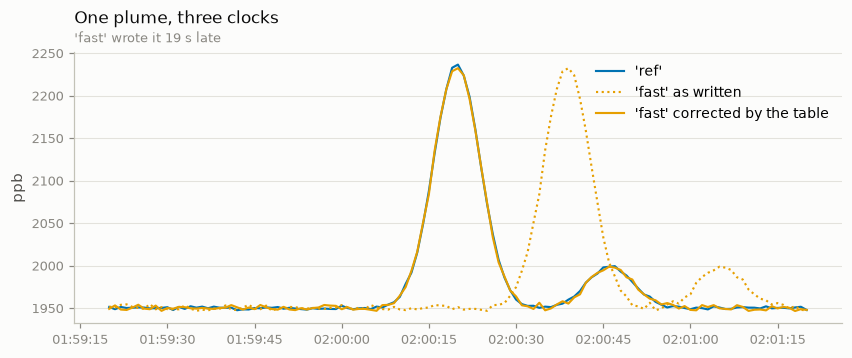

In [7]:
# Figure only: the tallest plume after the step, on the three clocks.
truth_ref = air.streams["ref"]["ch4"].to_series()
after = truth_ref[pd.Timestamp(STEP).tz_localize(None) :]
peak = after.idxmax()
window = slice(peak - pd.Timedelta("60s"), peak + pd.Timedelta("60s"))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(truth_ref[window].index, truth_ref[window], color=C1, label="'ref'")
written = as_written["fast"]["ch4"].to_series()[window]
fixed = corrected["fast"]["ch4"].to_series()[window]
ax.plot(written.index, written, color=C2, ls=":", label="'fast' as written")
ax.plot(fixed.index, fixed, color=C2, label="'fast' corrected by the table")
clock(ax, "%H:%M:%S")
finish(ax, "One plume, three clocks", f"'fast' wrote it {FAST_AFTER} s late", "ppb", legend=True)
plt.show()

The table is short, readable and exact: a person can check every row of it,
which is why the survey below writes one rather than applying what it
measures. At the defaults `fast`'s two rows leave 12 s between them, 01:00:07
to 01:00:19 on its recorded clock: a clock that jumps 12 s forward records
nothing in those seconds, so no row needs them. Readings no row holds keep their recorded times, and ingestion says
so twice: a warning naming the stretches, and the share in the stream's
`tsara_clock_uncorrected_share`.

**Try it.** Set `ROWS = "first"`: only the hour before the step is declared.
The warning lists the stretch after it, `fast` records 60 % of its readings
as uncorrected, and those readings stay 19 s late while the rest are right.

---
## §3 One segment's lag

The survey measures a lag one segment at a time, from the plumes two
instruments share (`METHODS.md` §12.4). On the archive of §2, as written:

1. each instrument's methane is put on **whole seconds** (each time floored,
   the first reading of each second kept), so a 1 s and a 2 s analyzer can be
   compared second by second without interpolating a gas;
2. its centred **running median is removed**, leaving the **wiggles**: the
   plumes without the slow background, which would otherwise decide the
   correlation;
3. the **whole-second peak** is the shift L, within the search, at which
   `fast`'s wiggles at t correlate best with `ref`'s at t − L. Positive L:
   `fast` shows the air later;
4. the **lag** is then measured again on the readings' own cells, at multiples
   of the **resolution** within 2 s of that peak: the peak says which second
   the clock error falls in, the cells say where inside it.

Steps 1 to 3 are compared with a plain loop written from their definition; the
lag, with the clock error the archive was written with, here 7.3 s, not a
whole number of seconds.

In [8]:
# ---- PARAMETERS (section 3) ----
SEGMENT_START = "2026-01-01T00:30:00Z"  # the half hour to measure
SEARCH = 60  # seconds searched either way
RUNNING_MEDIAN = 121  # seconds of the running median removed
FAST_ERROR = 7.3  # seconds 'fast' runs ahead in the first hour (19 after)
RESOLUTION = "0.1s"  # the step the lag is measured in

In [9]:
start_section("§3")
errors = (
    ("fast", "2026-01-01T00:00:00Z", "2026-01-01T01:00:00Z", FAST_ERROR),
    ("fast", "2026-01-01T01:00:00Z", "2026-01-01T03:00:00Z", 19),
    ("slow", "2026-01-01T00:00:00Z", "2026-01-01T03:00:00Z", -4),
)
air, manifest, _ = archive(errors)
streams = ingest_campaign(manifest)
first = int(pd.Timestamp(SEGMENT_START).timestamp())
stop = first + 1800

own = seconds_series(streams["fast"], "ch4", running_median_s=RUNNING_MEDIAN)
partner = seconds_series(streams["ref"], "ch4", running_median_s=RUNNING_MEDIAN)
lag = pooled_lag(
    [(own, partner)], first, stop, search_s=SEARCH, min_pairs=300, min_r=0.6, tolerance_s=2.0
)
print(f"whole seconds: peak at {lag.lag_s:+.0f} s, r {lag.r:.4f}, on {lag.n_pairs} paired seconds")

# Step 4: the lag again on the readings' own cells, at multiples of the
# resolution within 2 s of the peak. Each analyzer's noise is declared in the
# manifest, so it is taken out of the correlation first (METHODS.md §12.4).
fine, at_edge, removed = refined_lag(
    [
        (
            cell_series(streams["fast"], "ch4", running_median_s=RUNNING_MEDIAN),
            cell_series(streams["ref"], "ch4", running_median_s=RUNNING_MEDIAN),
        )
    ],
    first * 1_000_000_000,
    stop * 1_000_000_000,
    coarse_s=lag.lag_s,
    resolution_ns=pd.Timedelta(RESOLUTION).value,
    min_pairs=300,
)
print(
    f"on the readings' own cells, to {RESOLUTION}: lag {fine:+.2f} s"
    f" (declared noise removed: {'yes' if removed else 'no'})"
)

# The plain loops, on enough of each record to cover the segment and the search.
margin = pd.Timedelta(seconds=SEARCH + RUNNING_MEDIAN)
around = slice(
    pd.Timestamp(SEGMENT_START).tz_localize(None) - margin,
    pd.Timestamp(SEGMENT_START).tz_localize(None) + pd.Timedelta("30min") + margin,
)
ref_own = reference_wiggles(streams["fast"].sel(time=around), "ch4", RUNNING_MEDIAN)
ref_partner = reference_wiggles(streams["ref"].sel(time=around), "ch4", RUNNING_MEDIAN)
plain_lag, plain_r = reference_lag(ref_own, ref_partner, first, stop, SEARCH, 300)

inside = [s for s in range(first, stop) if s in ref_own]
package = np.array([own.values[s - own.first_s] for s in inside])
check(
    "§3 TSARA's wiggles equal the plain loop's at every second of the segment",
    np.allclose(package, [ref_own[s] for s in inside], equal_nan=False),
    f"{len(inside)} seconds",
)
check(
    "§3 TSARA's lag and r equal the plain loop's",
    lag.lag_s == plain_lag and np.isclose(lag.r, plain_r),
    f"{plain_lag:+d} s, r {plain_r:.4f}",
)
segment_start = pd.Timestamp(SEGMENT_START)
segment_end = segment_start + pd.Timedelta("30min")
step = pd.Timestamp("2026-01-01T01:00:00Z")
# Within the resolution; below about 0.05 s the noise decides, not the lattice.
allowed = max(pd.Timedelta(RESOLUTION).total_seconds(), 0.05)
claim = "§3 on the readings' own cells the lag is the clock error written, to the resolution"
if segment_end <= step or segment_start >= step:
    written = FAST_ERROR if segment_end <= step else 19
    check(
        claim,
        abs(fine - written) <= allowed,
        f"written {written:+g} s, measured {fine:+.2f} s, allowed ±{allowed:g} s",
    )
else:
    print(
        f"  – skipped: {claim[3:]}. This segment spans 'fast''s step at 01:00,"
        " so the archive was written with two errors in it"
    )

whole seconds: peak at +7 s, r 0.9983, on 1800 paired seconds
on the readings' own cells, to 0.1s: lag +7.30 s (declared noise removed: yes)


  ✔ §3 TSARA's wiggles equal the plain loop's at every second of the segment   [1800 seconds]
  ✔ §3 TSARA's lag and r equal the plain loop's   [+7 s, r 0.9983]
  ✔ §3 on the readings' own cells the lag is the clock error written, to the resolution   [written +7.3 s, measured +7.30 s, allowed ±0.1 s]


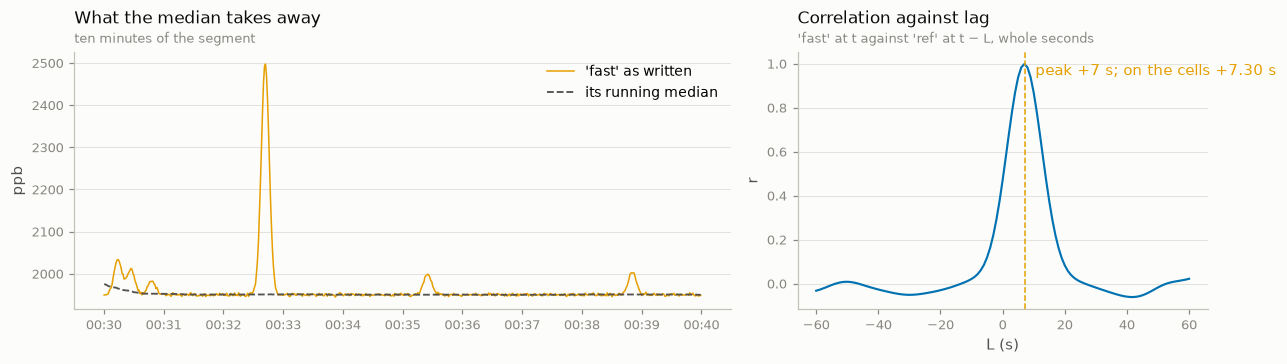

In [10]:
# Figure only.
curve = []
for shift in range(-SEARCH, SEARCH + 1):
    x = own.window(first, stop)
    y = partner.window(first - shift, stop - shift)
    ok = np.isfinite(x) & np.isfinite(y)
    curve.append(np.corrcoef(x[ok], y[ok])[0, 1] if ok.sum() >= 300 else np.nan)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
ten = slice(
    pd.Timestamp(SEGMENT_START).tz_localize(None),
    pd.Timestamp(SEGMENT_START).tz_localize(None) + pd.Timedelta("10min"),
)
raw = streams["fast"]["ch4"].to_series()[ten]
median = raw.rolling(f"{RUNNING_MEDIAN}s", center=True).median()
axes[0].plot(raw.index, raw, color=C2, lw=1, label="'fast' as written")
axes[0].plot(median.index, median, color=INK2, lw=1.2, ls="--", label="its running median")
clock(axes[0])
finish(axes[0], "What the median takes away", "ten minutes of the segment", "ppb", legend=True)
axes[1].plot(range(-SEARCH, SEARCH + 1), curve, color=C1)
axes[1].axvline(fine, color=C2, lw=1, ls="--")
axes[1].text(
    fine, lag.r, f"  peak {lag.lag_s:+.0f} s; on the cells {fine:+.2f} s", color=C2, va="top"
)
finish(
    axes[1],
    "Correlation against lag",
    "'fast' at t against 'ref' at t − L, whole seconds",
    "r",
    "L (s)",
)
fig.tight_layout()
plt.show()

The whole-second curve has one sharp peak, at the second the clock error
falls in, because the plumes are narrow: a few seconds off and they no longer
overlap. A best lag at the edge of the search is never decided, since the true
one may lie beyond it. Whole seconds cannot say where inside its second the
error lies (each reading's time was floored to put it there), so the lag is
measured again on the readings' own cells, and comes back as the 7.3 s the
archive was written with.

**Try it.** Set `RUNNING_MEDIAN = 11`: a median over 11 s follows a plume
rather than the background beneath it, so it takes much of each plume away.
The peak stays at +7 s but its r falls (0.92, against 1.00), and with it the
margin a segment has above the 0.6 it needs to be decided.

**Try it.** Set `RESOLUTION = "1s"` and `FAST_ERROR = 7.7`: the lag comes back
as +8 s, the nearest whole second.

---
## §4 The survey: every segment, the chain, the rows

`survey_clocks` measures every tier of every instrument on every segment, on
one grid of segments shared by all of them (`METHODS.md` §12.4). Its settings
live in a survey YAML of their own (`examples/configs/survey_example.yaml`);
here they are built in the setup cell: `fast` is measured against `ref`, and
`slow` against `fast` first, with `ref` directly as a backup tier that checks
it. `slow`'s lag against `fast` plus `fast`'s lag to `ref` is its lag to the
**reference clock**: the chain.

Consecutive segments whose lags agree become one row of the table; a jump is a
**clock step**, and the two rows meet at the longest gap in the readings
across it, where a logger stopped or its clock jumped, rather than at a
segment edge.

In [11]:
# ---- PARAMETERS (section 4) ----
SEGMENT = "30min"  # one lag per segment of this length
MIN_R = 0.6  # the correlation a segment needs to be decided
TOLERANCE = "2s"  # lags agreeing within this are one row

In [12]:
start_section("§4")
errors = (
    ("fast", "2026-01-01T00:00:00Z", "2026-01-01T01:00:00Z", 7),
    ("fast", "2026-01-01T01:00:00Z", "2026-01-01T03:00:00Z", 19),
    ("slow", "2026-01-01T00:00:00Z", "2026-01-01T03:00:00Z", -4),
)
air, manifest, exported = archive(errors)
streams = ingest_campaign(manifest)
survey = survey_clocks(streams, survey_settings(SEGMENT, MIN_R, TOLERANCE))

columns = ["instrument", "start", "tier", "partner", "lag_s", "lag_to_reference_s", "status"]
print(survey.segments[columns].to_string(index=False))
print("\nrows:")
for row in survey.rows:
    print(" ", row.instrument, row.describe())
print("\nfaults:")
print(survey.faults.to_string(index=False) if len(survey.faults) else "  none")
print()

truth = {(r.instrument, r.shift_ns) for r in read_clock_corrections([exported])}
check(
    "§4 the survey's shifts are minus the clock errors the archive was written with",
    {(r.instrument, r.shift_ns) for r in survey.rows} == truth,
)
fast_rows = [r for r in survey.rows if r.instrument == "fast"]
times = streams["fast"]["time"].values.astype("datetime64[ns]").astype("int64")
after_hole = int(times[times >= pd.Timestamp("2026-01-01T01:00:19").value][0])
check(
    "§4 'fast''s two rows meet at the first reading after its step, not at a segment edge",
    len(fast_rows) == 2 and fast_rows[0].end_ns == fast_rows[1].start_ns == after_hole,
    pd.Timestamp(after_hole).strftime("%H:%M:%S"),
)
slow = survey.segments[
    (survey.segments.instrument == "slow") & (survey.segments.status == "decided")
]
check(
    "§4 'slow', measured against 'fast', reaches the reference clock through the chain",
    len(slow) > 0 and (slow.lag_to_reference_s == -4).all(),
    f"{len(slow)} decided segments at -4 s",
)
# The backup tier: 'slow' measured against 'ref' directly, beside the lag the
# chain gives it ('slow' against 'fast', plus 'fast''s own lag to 'ref').
m = survey.measurements
backup = m[(m.instrument == "slow") & (m.tier == 2) & m.decided].set_index("start").lag_s
chained = survey.segments[survey.segments.instrument == "slow"].set_index("start")
side = pd.DataFrame(
    {
        "against 'fast'": chained.lag_s,
        "chained to 'ref'": chained.lag_to_reference_s,
        "backup, against 'ref'": backup,
        "status": chained.status,
    }
).dropna(subset=["chained to 'ref'", "backup, against 'ref'"], how="all")
print("\n'slow', segment by segment:")
print(side.to_string())
print()

# A segment of 'slow' whose search reaches across 'fast''s step compares 'slow'
# with a partner that changed clock part-way through: the chain is not to be
# trusted there, which is what the backup tier is for. Everywhere else the two
# routes should agree.
boundary = pd.Timestamp(fast_rows[0].end_ns)
search = pd.Timedelta(survey.config.search)
starts = pd.to_datetime(pd.Series(side.index, index=side.index)).dt.tz_localize(None)
away = (starts - search > boundary) | (starts + pd.Timedelta(SEGMENT) + search <= boundary)
gap = (side["backup, against 'ref'"] - side["chained to 'ref'"]).abs()
tolerance = pd.Timedelta(TOLERANCE).total_seconds()
check(
    "§4 its backup tier agrees with the chain wherever 'fast' keeps one clock",
    away.sum() > 0 and gap[away].notna().all() and (gap[away] <= tolerance).all(),
    f"{int(away.sum())} segment(s), largest difference {gap[away].max():g} s",
)
disagree = survey.faults[
    (survey.faults.instrument == "slow") & (survey.faults.kind == "tiers disagree")
]
near_step = (pd.to_datetime(disagree.start).dt.tz_localize(None) - search <= boundary) & (
    boundary < pd.to_datetime(disagree.end).dt.tz_localize(None) + search
)
check(
    "§4 where the two routes disagree, it is where 'fast' steps, and the survey names it",
    near_step.all(),
    f"{len(disagree)} disagreement(s)",
)

instrument                start  tier partner  lag_s  lag_to_reference_s    status
      fast 2026-01-01T00:00:00Z     1     ref    7.0                 7.0   decided
      fast 2026-01-01T00:30:00Z     1     ref    7.0                 7.0   decided
      fast 2026-01-01T01:00:00Z     1     ref   19.0                19.0   decided
      fast 2026-01-01T01:30:00Z     1     ref   19.0                19.0   decided
      fast 2026-01-01T02:00:00Z     1     ref   19.0                19.0   decided
      fast 2026-01-01T02:30:00Z  <NA>            NaN                 NaN too short
      slow 2025-12-31T23:30:00Z  <NA>            NaN                 NaN too short
      slow 2026-01-01T00:00:00Z     1    fast  -11.0                -4.0   decided
      slow 2026-01-01T00:30:00Z     1    fast  -11.0                -4.0   decided
      slow 2026-01-01T01:00:00Z     1    fast  -23.0                -4.0   decided
      slow 2026-01-01T01:30:00Z     1    fast  -23.0                -4.0   decided
    

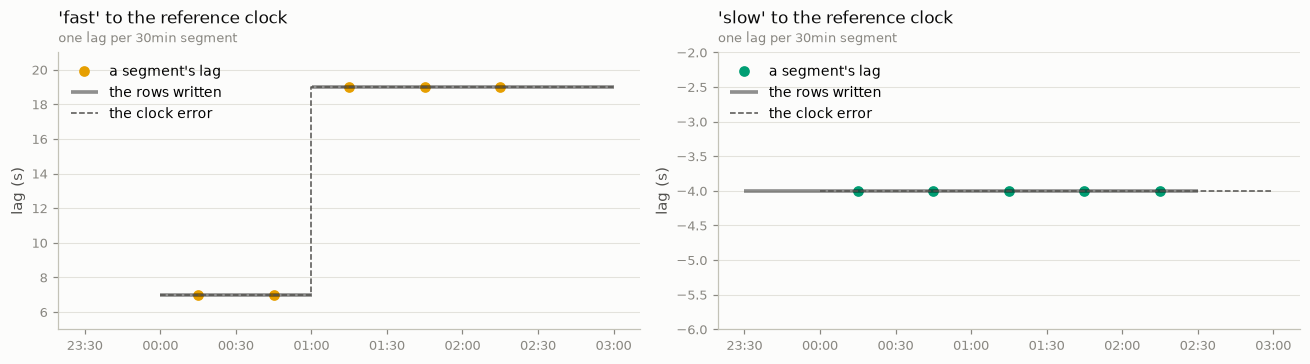

In [13]:
# Figure only.
truth_line = {
    "fast": pd.Series(
        [7, 7, 19, 19],
        index=pd.to_datetime(
            ["2026-01-01 00:00", "2026-01-01 01:00", "2026-01-01 01:00", "2026-01-01 03:00"]
        ),
    ),
    "slow": pd.Series([-4, -4], index=pd.to_datetime(["2026-01-01 00:00", "2026-01-01 03:00"])),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharex=True)
for ax, name, color in zip(axes, ("fast", "slow"), (C2, C3)):
    lag_panel(ax, survey, name, truth_line[name], color)
    finish(
        ax,
        f"'{name}' to the reference clock",
        f"one lag per {SEGMENT} segment",
        "lag (s)",
        legend=True,
        loc="upper left",
    )
fig.tight_layout()
plt.show()

Each point is one segment's lag to the reference clock, the solid lines are
the rows the survey wrote (minus their shift), and the dashed line is the
error the archive was written with. The survey wrote one row for `slow` and
two for `fast`, and named the step between them. The table of `slow`'s
segments shows the backup tier at work: −11 s against `fast` before the step
and −23 s after, plus `fast`'s own lag, is −4 s to the reference clock
throughout, and the backup tier, measured against `ref` directly, says −4 s
in every segment too. The record's first and last half hours hold only a few
readings each, too few to measure (tier `<NA>`: no tier measured them); they
are not undecided, and the rows reach over them.

**Try it.** Set `SEGMENT = "10min"`: three times as many segments, the same
rows, and the step still on the reading after the hole, because the boundary
follows the readings, not the segment grid. One thing more appears: the
`slow` segment ending at 01:00 is compared with `fast` 11 s later, which
reaches across `fast`'s step, so its lag through the chain comes out wrong
(0 s, not −4 s; the 00:50 row of `slow`'s table). The backup tier against
`ref` still says −4 s there and names the disagreement, and the segment is set
aside as an outlier against its two neighbours, so the rows do not move.

---
## §5 What the survey names instead of fitting

A clock does not only jump. Here three instruments are built by hand from one
sequence of plumes, each recording them on a clock that misbehaves in its own
way, against `ref` on the right one (`METHODS.md` §12.5):

* `drifting` gains a few seconds an hour, smoothly;
* `odd` is 4 s late, except for one segment where a coincidence of plumes
  would read 12 s;
* `gappy` is 5 s late, but its methane is missing for ten minutes while it
  logs other things.

The survey turns each into rows and names what it saw.

In [14]:
# ---- PARAMETERS (section 5) ----
DRIFT_PER_HOUR = 6.0  # seconds 'drifting' gains each hour
OUTLIER = 12.0  # the lag of 'odd''s one strange segment, where the rest are 4 s
TOLERANCE = "2s"  # lags agreeing within this are one row
RESOLUTION = "1s"  # the step each segment's lag is measured in

In [15]:
start_section("§5")
N = 5400  # an hour and a half of 1 s readings: nine 10-minute segments
rng = np.random.default_rng(3)
plumes = np.zeros(N + 200)
for centre in rng.choice(N, size=N // 30, replace=False):
    plumes += rng.lognormal(3, 0.5) * np.exp(-0.5 * ((np.arange(N + 200) - centre) / 3.0) ** 2)


def recorded(late, seed, missing=None):
    """Return readings of the plume at true second t, written at t + late(t)."""
    t = np.arange(N, dtype=float)
    values = plumes[:N] + np.random.default_rng(seed).normal(0, 0.3, N)
    if missing is not None:
        values[(t >= missing[0]) & (t < missing[1])] = np.nan
    times = START + pd.to_timedelta(t + late(t), unit="s")
    order = np.argsort(np.asarray(times))
    return xr.Dataset(
        {"ch4": ("time", values[order]), "other": ("time", np.ones(N))},
        coords={"time": np.asarray(times)[order]},
    )


drift = lambda t: 1.0 + DRIFT_PER_HOUR * t / 3600  # noqa: E731
odd = lambda t: np.where((t >= 1800) & (t < 2400), OUTLIER, 4.0)  # noqa: E731
streams = {
    "ref": recorded(lambda t: 0.0 * t, 1),
    "drifting": recorded(drift, 2),
    "odd": recorded(odd, 3),
    "gappy": recorded(lambda t: 5.0 + 0.0 * t, 4, missing=(3000, 3600)),
}
config = SurveyConfig.model_validate(
    {
        "reference_clock": "ref",
        "tracers": {
            name: [{"partner": "ref", "pairs": [["ch4", "ch4"]]}]
            for name in streams
            if name != "ref"
        },
        "segment": "10min",
        "search": "30s",
        "min_pairs": 200,
        "running_median": "61s",
        "tolerance": TOLERANCE,
        "resolution": RESOLUTION,
    }
)
survey = survey_clocks(streams, config)
for row in survey.rows:
    print(" ", row.instrument, row.describe())
print()
print(survey.faults.to_string(index=False))
print()


def rows_of(name):
    """Return the survey's rows for one instrument."""
    return [r for r in survey.rows if r.instrument == name]


drifting = rows_of("drifting")
# Within the resolution; below about 0.05 s the noise decides, not the lattice.
allowed = max(pd.Timedelta(RESOLUTION).total_seconds(), 0.05)
if len(drifting) == 1 and drifting[0].shift_end_ns is not None:
    start_s = (drifting[0].start_ns - START.value) / 1e9
    end_s = (drifting[0].end_ns - START.value) / 1e9
    written = (-drifting[0].shift_ns / 1e9, -drifting[0].shift_end_ns / 1e9)
    check(
        "§5 a slow drift is one row whose shift runs within the resolution of the truth",
        abs(written[0] - drift(start_s)) <= allowed and abs(written[1] - drift(end_s)) <= allowed,
        f"{written[0]:+.2f} s to {written[1]:+.2f} s, truth {drift(start_s):+.2f} s to "
        f"{drift(end_s):+.2f} s, allowed ±{allowed:g} s",
    )
else:
    check(
        "§5 a drift faster than the tolerance per segment is named a fast drift",
        (survey.faults.kind == "fast drift").any(),
    )
odd_status = survey.segments[survey.segments.instrument == "odd"].status.tolist()
check(
    "§5 one segment against two agreeing neighbours is set aside, and the row runs on",
    "outlier" in odd_status and len(rows_of("odd")) == 1 and rows_of("odd")[0].shift_ns == -4e9,
)
undecided = survey.faults[
    (survey.faults.instrument == "gappy") & (survey.faults.kind == "undecided")
]
check(
    "§5 a stretch with readings but no tracer ends the row and is named",
    len(rows_of("gappy")) == 2 and list(undecided.start) == ["2026-01-01T00:50:00Z"],
    "00:50 to 01:00 left uncorrected",
)
check(
    "§5 every fault named is one of the kinds the survey knows",
    set(survey.faults.kind) <= set(FAULT_KINDS),
)

  drifting 2026-01-01T00:00:00Z/2026-01-01T01:40:00Z shift -0.905556 s to -11.2389 s onto ref (measured; clock survey: 9 segments, tier 1, lags +1 to +9 s)
  odd 2026-01-01T00:00:00Z/2026-01-01T01:40:00Z shift -4 s onto ref (measured; clock survey: 8 segments, tier 1, lags +4 to +4 s)
  gappy 2026-01-01T00:00:00Z/2026-01-01T00:50:00Z shift -5 s onto ref (measured; clock survey: 5 segments, tier 1, lags +5 to +5 s)
  gappy 2026-01-01T01:00:00Z/2026-01-01T01:40:00Z shift -5 s onto ref (measured; clock survey: 3 segments, tier 1, lags +5 to +5 s)

instrument        kind                start                  end                                    detail
  drifting clock drift 2026-01-01T00:00:00Z 2026-01-01T01:30:00Z lag +0.91 s to +11.24 s, +6.20 s per hour
       odd     outlier 2026-01-01T00:30:00Z 2026-01-01T00:40:00Z              lag +12 s against neighbours
     gappy   undecided 2026-01-01T00:50:00Z 2026-01-01T01:00:00Z                         1 no tier decided

  ✔ §5 a slow drift 

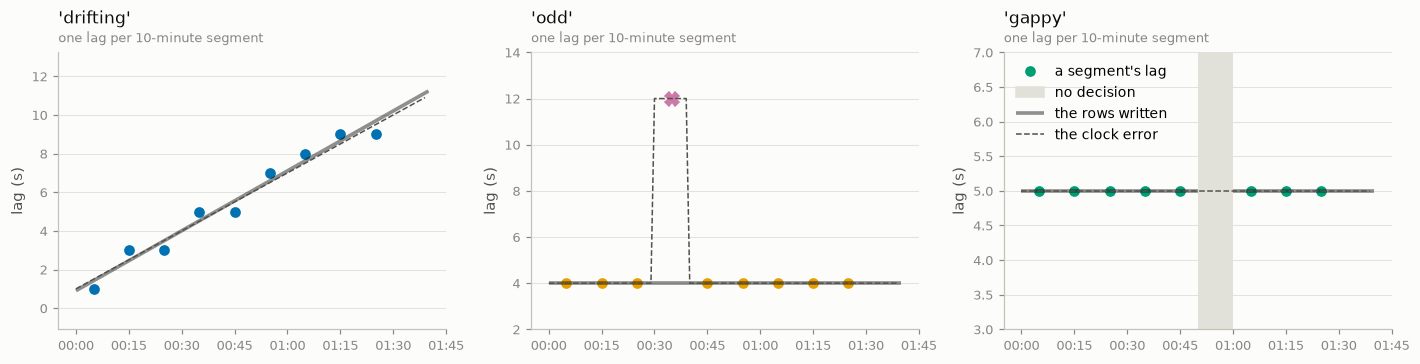

In [16]:
# Figure only.
t = np.arange(0, N + 600, 60.0)
truths = {
    "drifting": pd.Series(drift(t), index=START + pd.to_timedelta(t, unit="s")),
    "odd": pd.Series(odd(t), index=START + pd.to_timedelta(t, unit="s")),
    "gappy": pd.Series(5.0, index=START + pd.to_timedelta(t, unit="s")),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharex=True)
for ax, (name, truth), color in zip(axes, truths.items(), (C1, C2, C3)):
    lag_panel(ax, survey, name, truth, color)
    finish(
        ax,
        f"'{name}'",
        "one lag per 10-minute segment",
        "lag (s)",
        legend=name == "gappy",
        loc="upper left",
    )
fig.tight_layout()
plt.show()

`drifting` becomes one row with a `shift_end`: the shift runs linearly across
it, as a drifting clock's error does. Each segment's lag is measured to the
resolution, here a whole second, and this clock's true lag at the middle of
every segment is a half second (1.5, 2.5, …), so each point sits exactly half
a second above or below the true line. The row's line through them, evaluated
at the row's own ends (which here reach over the record's short last segment),
still lands within a quarter second of the truth at both ends, and its rate
comes out 6.2 s an hour against the 6.0 written. `odd`'s strange segment is set aside
against its two agreeing neighbours, and stays inside the row around it: one
segment against two is more likely a coincidence of plumes than two clock
steps in a row. `gappy`'s ten minutes without methane end its first row; the
survey writes nothing for them, so ingestion will leave them as recorded and
say so.

**Try it.** Set `RESOLUTION = "0.1s"`: each point now sits within 0.1 s of
the true line, and the row lands within 0.03 s of the truth at both ends, at
5.99 s an hour.

**Try it.** Set `TOLERANCE = "0.5s"`: `drifting` now gains more than the
tolerance between segments, so instead of one drifting row it gets six short
ones of one or two segments, a clock step between each, and the survey names
the run of same-signed steps a *fast drift* (a shorter segment, or a larger
tolerance, resolves it).

---
## §6 The loop closed

What the survey is for: measure a campaign ingested as written, save what it
found, read the table, name it in the manifest, ingest again. `save_clock_survey`
writes the table beside the evidence for every row (the measurements, the
segments, the faults, the settings), in a bundle's `survey/` directory.

Surveyed again, a corrected campaign is an **after-check**: every lag should be
zero, and no rows are derived from streams that already carry a table.

In [17]:
# ---- PARAMETERS (section 6) ----
SEGMENT = "30min"  # one lag per segment of this length

In [18]:
start_section("§6")
errors = (
    ("fast", "2026-01-01T00:00:00Z", "2026-01-01T01:00:00Z", 7),
    ("fast", "2026-01-01T01:00:00Z", "2026-01-01T03:00:00Z", 19),
    ("slow", "2026-01-01T00:00:00Z", "2026-01-01T03:00:00Z", -4),
)
air, manifest, _ = archive(errors)
survey = survey_clocks(ingest_campaign(manifest), survey_settings(SEGMENT))

bundle = Path(tempfile.mkdtemp()) / "bundle"
folder = save_clock_survey(survey, bundle)
print("survey/ holds:", sorted(p.name for p in folder.iterdir()), "\n")
print((folder / "clock_corrections.csv").read_text())

back = load_clock_survey(bundle)
check(
    "§6 a saved survey reloads exactly: its tables, its settings, its rows",
    all(getattr(back, n).equals(getattr(survey, n)) for n in ("measurements", "segments", "faults"))
    and back.config == survey.config
    and [(r.start_ns, r.end_ns, r.shift_ns) for r in back.rows]
    == [(r.start_ns, r.end_ns, r.shift_ns) for r in survey.rows],
)

table = folder / "clock_corrections.csv"
corrected = ingest_campaign(manifest.model_copy(update={"clock_corrections": (table,)}))
check(
    "§6 the survey's own table puts every reading of every instrument on its true time",
    all(
        np.array_equal(corrected[n]["time"].values, air.streams[n]["time"].values)
        for n in air.streams
    ),
)
again = survey_clocks(corrected, survey_settings(SEGMENT))
residuals = again.segments.lag_to_reference_s.dropna()
check(
    "§6 surveyed again, every decided lag is zero and no rows are derived",
    len(residuals) > 0 and (residuals == 0).all() and again.rows == (),
    f"{len(residuals)} segments",
)
print()
print(again.faults[["instrument", "kind", "detail"]].to_string(index=False))

survey/ holds: ['clock_corrections.csv', 'faults.parquet', 'measurements.parquet', 'segments.parquet', 'survey.yaml'] 

instrument,start,end,shift,shift_end,reference_clock,provenance,reason
fast,2026-01-01T00:00:00Z,2026-01-01T01:00:19Z,-7s,,ref,measured,"clock survey: 2 segments, tier 1, lags +7 to +7 s"
fast,2026-01-01T01:00:19Z,2026-01-01T03:00:00Z,-19s,,ref,measured,"clock survey: 3 segments, tier 1, lags +19 to +19 s"
slow,2025-12-31T23:30:00Z,2026-01-01T02:30:00Z,4s,,ref,measured,"clock survey: 5 segments, tier 1, lags -4 to -4 s"

  ✔ §6 a saved survey reloads exactly: its tables, its settings, its rows
  ✔ §6 the survey's own table puts every reading of every instrument on its true time


  ✔ §6 surveyed again, every decided lag is zero and no rows are derived   [10 segments]

instrument        kind                                                                                    detail
      fast after-check the stream carries clock corrections already: measured as an after-check, no rows derived
      slow after-check the stream carries clock corrections already: measured as an after-check, no rows derived


The manifest here names the table straight from the bundle, which is safe
only because the answer is known. On a real campaign the table is copied
beside the manifest, read and corrected by a person, and the copy is what the
manifest names.

That is the whole of Phase 3.6's machinery: a table declared beside the
manifest and applied as each file is read (§2), and a survey that measures it
from the data (§3–§5) and writes it for a person to review (§6). What comes
next is the real campaign: the SLC-SOS van, read from its analyzers' own logs,
surveyed against its GPS-timed weather station.

---
## Scoreboard

Every check printed above, gathered: each line a claim about TSARA, compared
as it ran against a reference written independently in this notebook or the
clock error the archive was written with.

In [19]:
held = sum(ok for ok, _ in CHECKS.values())
print(f"{held} of {len(CHECKS)} checks hold\n")
for claim, (ok, detail) in CHECKS.items():
    print(f"  {'✔' if ok else '✘'} {claim}" + (f"   [{detail}]" if detail else ""))

19 of 19 checks hold

  ✔ §2 as written, each reading sits its clock error after its true time   ['fast' 7 s then 19 s, 'slow' -4 s]
  ✔ §2 with the table, every reading a row holds is on its true time, and only those   [100% of 'fast' held]
  ✔ §2 the stream records the share of readings no row held   [0.0%]
  ✔ §2 the reference clock's instrument is left alone and carries no clock attributes
  ✔ §3 TSARA's wiggles equal the plain loop's at every second of the segment   [1800 seconds]
  ✔ §3 TSARA's lag and r equal the plain loop's   [+7 s, r 0.9983]
  ✔ §3 on the readings' own cells the lag is the clock error written, to the resolution   [written +7.3 s, measured +7.30 s, allowed ±0.1 s]
  ✔ §4 the survey's shifts are minus the clock errors the archive was written with
  ✔ §4 'fast''s two rows meet at the first reading after its step, not at a segment edge   [01:00:19]
  ✔ §4 'slow', measured against 'fast', reaches the reference clock through the chain   [5 decided segments at -4 s]